In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
from google.colab import files
files.upload()

df = pd.read_csv('spam.csv', encoding='latin-1')
df.head()

Saving spam.csv to spam (1).csv


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df = df[['v1', 'v2']]
df.columns = ['label', 'text']
print(df.shape)

(5572, 2)


label    0
text     0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


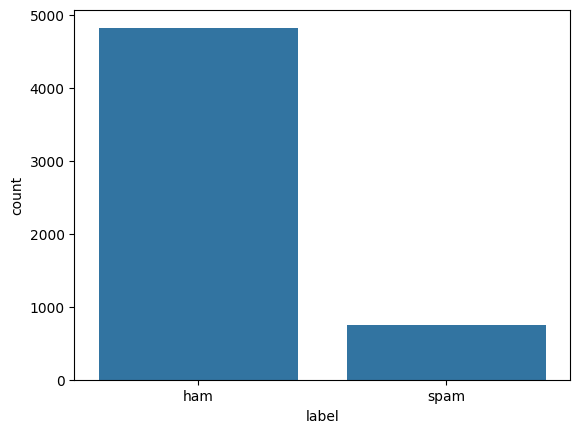

In [ ]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['label'].value_counts())

sns.countplot(x='label', data=df)
plt.show()

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

In [ ]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].head()

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [ ]:
X = df['clean_text']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)

lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

                 Model  Accuracy  Precision  Recall      F1
0          Naive Bayes    0.9710     0.9810  0.7863  0.8729
1  Logistic Regression    0.9749     0.8889  0.9160  0.9023
              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       903
        spam       0.89      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.94      0.95      0.94      1034
weighted avg       0.98      0.97      0.98      1034



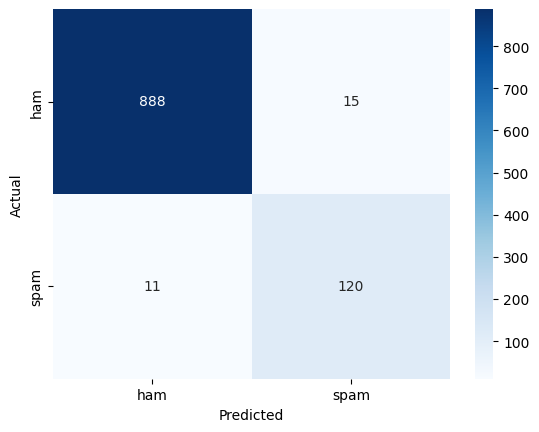

In [ ]:
results = []
for name, model in [('Naive Bayes', nb), ('Logistic Regression', lr)]:
    pred = model.predict(X_test_tfidf)
    results.append([name,
                    accuracy_score(y_test, pred),
                    precision_score(y_test, pred),
                    recall_score(y_test, pred),
                    f1_score(y_test, pred)])

print(pd.DataFrame(results,
      columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1']).round(4))

best_pred = lr.predict(X_test_tfidf)
print(classification_report(y_test, best_pred, target_names=['ham', 'spam']))

sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt='d',
            cmap='Blues', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
def predict_sms(message, model=lr):
    cleaned = clean_text(message)
    vec = tfidf.transform([cleaned])
    return 'SPAM' if model.predict(vec)[0] == 1 else 'HAM (not spam)'

print(predict_sms("Congratulations! You won a free prize. Call now to claim!"))
print(predict_sms("Hey, are we still meeting for lunch tomorrow?"))

SPAM
HAM (not spam)
